# Challenge: Processing of Tabular Data 

__Import Statements__

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt

## Read the data

> **Challenge:** Read the `IHME_GBD_2016_POPULATION_ESTIMATES_1990_2016_Y2017M09D14.CSV` file stored in the `../data/` folder and store it to a variable namend `pop`. _Hint: Use the_ `pd.read_csv` _function._ 

In [ ]:
## your code here

In [3]:
# %load ../src/_solutions/tab_data01.py
pop = pd.read_csv("../data/IHME_GBD_2016_POPULATION_ESTIMATES_1990_2016_Y2017M09D14.CSV")
pop


,location_id,location_name,sex_id,sex_name,age_group_id,age_group_name,year_id,pop
0,1,Global,1,Male,1,Under 5,1990,3.073378e+08
1,1,Global,2,Female,1,Under 5,1990,2.911299e+08
2,1,Global,3,Both,1,Under 5,1990,5.984677e+08
3,1,Global,1,Male,1,Under 5,1991,3.089656e+08
4,1,Global,2,Female,1,Under 5,1991,2.921822e+08
...,...,...,...,...,...,...,...,...
603931,44639,Middle SDI,2,Female,235,95 plus,2015,3.984956e+05
603932,44639,Middle SDI,3,Both,235,95 plus,2015,5.625882e+05
603933,44639,Middle SDI,1,Male,235,95 plus,2016,1.766505e+05
603934,44639,Middle SDI,2,Female,235,95 plus,2016,4.302028e+05


## Inspect the data

> **Challenge:** Inspect the data by 
> * printing the column names
> * counting the number of unique entries in the `location_name` column
> * printing some location names
> * figuring out the unique categories for the `sex_name` and `age_group` columns

> _Hint_: the `pd.DataFrame` attributes and methods: `.columns`, `.nunique()`, `.unique()`, `.sample()` may come handy


### Exploratory Data Analysis

* printing the column names

In [ ]:
## your code here

In [5]:
list(pop.columns)

['location_id',
 'location_name',
 'sex_id',
 'sex_name',
 'age_group_id',
 'age_group_name',
 'year_id',
 'pop']

* counting the number of unique entries in the `location_name` column

In [8]:
pop['location_name'].nunique()

231

In [ ]:
## your code here

* printing some location names

In [ ]:
## your code here

* figuring out the unique categories for the `sex_name` and `age_group` columns

In [ ]:
## your code here

In [15]:
# %load ../src/_solutions/tab_data02.py
#pop.columns
#pop["location_name"].nunique()
#pop["location_name"].sample(10)
print(pop["sex_name"].unique())
print(pop["age_group_name"].unique())


['Male' 'Female' 'Both']
['Under 5' 'Early Neonatal' 'Late Neonatal' 'Post Neonatal' '1 to 4'
 '5 to 9' '10 to 14' '15 to 19' '20 to 24' '25 to 29' '30 to 34'
 '35 to 39' '40 to 44' '45 to 49' '50 to 54' '55 to 59' '60 to 64'
 '65 to 69' '70 to 74' '75 to 79' 'All Ages' '5-14 years' '15-49 years'
 '50-69 years' '70+ years' '<1 year' '80 to 84' '85 to 89' '90 to 94'
 '<20 years' '10-24 years' '95 plus']


## Analyzing a subset of the dataset

> **Challenge:** Subset the data set based on age groups, location and sex as given below and save the resulting  data frame to a variable called `pop_subset`. 

> _Hint_: You can check for values being included in a list of elements using `df[column].isin(my_list)` 

> _Hint_: You can combine `pd.Series` (columns) with a `dtype` of `bool` using:
> - `&` (and)
>   - `True & True == True`
>   - `True & False == False`
>   - `False & False == False`
> - `|` (or)
>   - `True | True == True`
>   - `True | False == True`
>   - `False | False == False`
>     
> E.g. `df[column].isin(my_list) & df[column].isin(my_other_list)` will only be `True` for rows where the `column` value is in both lists

__Subsetting__

In [18]:
ages = ['5-14 years', '15-49 years', '50-69 years','70+ years']
location = ["Germany", "France", "Italy"]
sex = ['Male', 'Female']

In [19]:
## your code here

In [21]:
cond = (
    pop["age_group_name"].isin(ages) & 
    pop["location_name"].isin(location) & 
    pop["sex_name"].isin(sex)
)

cond

0         False
1         False
2         False
3         False
4         False
          ...  
603931    False
603932    False
603933    False
603934    False
603935    False
Length: 603936, dtype: bool

In [20]:
# %load ../src/_solutions/tab_data03.py
cond = (
    pop["age_group_name"].isin(ages) & 
    pop["location_name"].isin(location) & 
    pop["sex_name"].isin(sex)
)

pop_subset = pop.loc[cond]
print(pop_subset.shape)
pop_subset.sample(5)


(648, 8)


,location_id,location_name,sex_id,sex_name,age_group_id,age_group_name,year_id,pop
217011,86,Italy,1,Male,25,50-69 years,1994,6359369.27
216969,86,Italy,1,Male,24,15-49 years,2007,13828699.00
216904,86,Italy,2,Female,23,5-14 years,2012,2718458.12
204009,81,Germany,1,Male,24,15-49 years,2007,19433560.30
201358,80,France,2,Female,23,5-14 years,2014,3874590.71


### Split-Apply-Combine

![](img/split-apply-combine.svg)

Image source: [Jake VanderPlas 2016, Data Science Handbook](https://jakevdp.github.io/PythonDataScienceHandbook/)

### Multi-Index Dataframes

To showcase the handling of Multi-Index Dataframes we load a toy dataset contained in the file `data_unstack.csv` in the data folder of the current session.

In [22]:
df_unstack = pd.read_csv('../data/data_unstack.csv')

In [23]:
df_unstack

,Names,Age,Country,Money,Year
0,Alice,25,Germany,5500,1990
1,Alice,25,Germany,500,1990
2,Bob,21,France,2000,1990
3,Charlie,28,Spain,3000,1990
4,David,46,UK,4000,1990
5,Alice,25,Germany,7500,1995
6,Bob,21,France,1000,1995
7,Bob,21,France,-500,1995
8,Charlie,28,Spain,2500,1995
9,David,46,UK,8000,1995


If we groupby the column `Names` and apply the aggregation method `sum` over the column `Money` we get the total amount of money for each name in the dataset.

In [34]:
df_unstack.groupby(['Year', 'Names'])['Money'].sum().unstack()

Names,Alice,Bob,Charlie,David
Year,,,,
1990,6000,2000,3000,4000
1995,7500,500,2500,9000
2000,10500,2000,2000,7000


But what happens if we groupby the columns `Year` and `Names` over the column `Money`? In this case `groupby()` returns a Multi-Index Dataframe containing the total sum for each year and each name in the dataset. In order to return to our familiar format for tabular data we can use the `unstack()` method. Let´s familiarize ourselves with Multi-Index Dataframes!

> **Challenge:** Load the dataset in `'../data/data_unstack.csv'` groupby the columns `'Year'` and `'Names'` and aggregate with `sum()` over the column `'Money'`. Use `unstack()`-method to reform the dataframe so the `'Year'`-Column is set as Index.

In [ ]:
## your code here

In [10]:
# %load ../src/_solutions/unstack_example.py

> **Challenge:** Compute the population of Germany, Italy and France for the years 1990 to 2016. 

> _Hint_: Use the `groupby` function. You can also pass multiple columns to it by passing a `list`

> _Hint_: When passing multiple columns you will end up with an ugly `MultiIndex`. You can transform an `index` level to columns using the `.unstack(level)` method. With `level = 0` being the leftmost index, `level = 1` the second from left, etc.


In [ ]:
## your code here

In [40]:
# %load ../src/_solutions/tab_data04.py
gb = pop_subset.groupby(["year_id", "location_name"])["pop"].sum()
gb = gb.unstack()
gb

location_name,France,Germany,Italy
year_id,,,
1990,52924678.45,74905392.07,53965720.67
1991,53204997.81,75282202.61,54096588.22
1992,53491245.78,75846260.69,54185851.15
1993,53764681.77,76382332.04,54181997.23
1994,54014103.00,76711513.38,54185577.66
1995,54244201.26,77017974.10,54196349.68
1996,54453151.38,77271569.64,54215293.54
1997,54652082.22,77347967.36,54261314.98
1998,54837898.37,77306087.32,54309603.01


## Plotting

> **Challenge:**    
Plot how the the population of Germany, Italy and France changed over the years 1990 to 2016. 

*Hint*: Use `unstack()` to deal with multi-Index dataframes : [Documentation unstack()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.unstack.html)

In [ ]:
## your code here

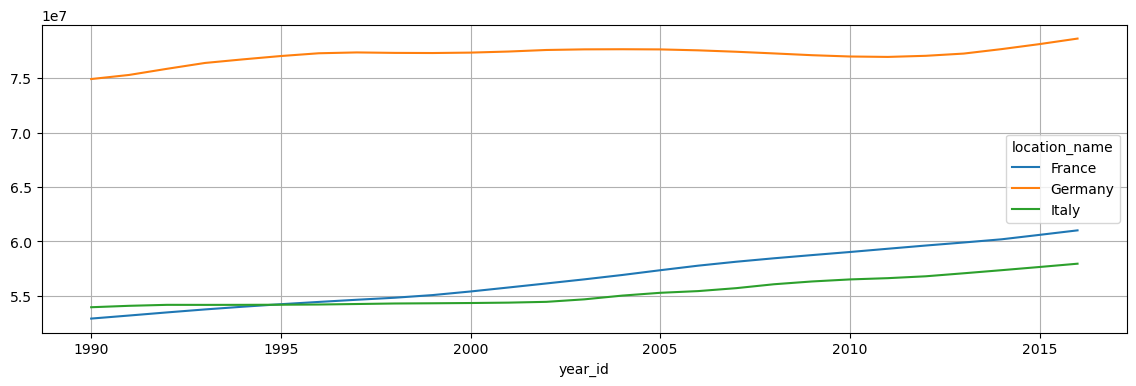

In [41]:
# %load ../src/_solutions/tab_data05.py
gb.plot(figsize=(14,4))
plt.grid()


> **Challenge:** Redo the analysis from above but now include Spain in addition to Germany, Italy and France into the analysis.

## Solution:
- Append `'Spain'` into the location list and rerun the code above

In [ ]:
location = ["Germany", "France", "Italy"]

In [ ]:
## your code here

In [ ]:
# %load ../src/_solutions/challenge0.py

> **Challenge:** Plot the the population for all age groups between 1990-2016.

In [ ]:
#your code here...

In [ ]:
# %load ../src/_solutions/challenge1.py

> **Challenge:** Plot the the population for `'5-14 years'` and `'70+ years'` for germany between 1990-2016.

In [ ]:
# your code here...

(108, 8)
        location_id location_name  sex_id sex_name  age_group_id  \
204153           81       Germany       1     Male            26   
203946           81       Germany       1     Male            23   
204168           81       Germany       1     Male            26   
204151           81       Germany       2   Female            26   
203926           81       Germany       2   Female            23   

       age_group_name  year_id         pop  
204153      70+ years     2001  3302679.24  
203946     5-14 years     2013  3726828.13  
204168      70+ years     2006  3991793.64  
204151      70+ years     2000  6140386.42  
203926     5-14 years     2006  3874319.22  
year_id  age_group_name
1990     5-14 years         8335403.58
         70+ years          7974145.26
1991     5-14 years         8476378.18
         70+ years          8126064.93
1992     5-14 years         8642410.14
         70+ years          8265748.44
1993     5-14 years         8811810.78
         70+ ye

<Axes: xlabel='year_id'>

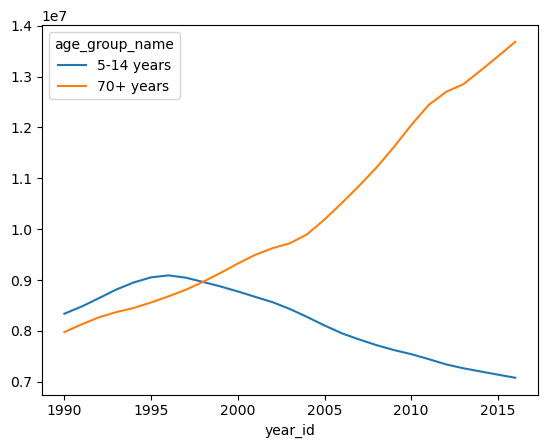

In [49]:
# %load ../src/_solutions/challenge2.py
ages = ['5-14 years','70+ years']
location  = ['Germany']
sex = ['Male', 'Female']

cond = (
    pop["age_group_name"].isin(ages) & 
    pop["location_name"].isin(location) & 
    pop["sex_name"].isin(sex)
)

pop_subset2 = pop.loc[cond,:]
print(pop_subset2.shape)
print(pop_subset2.sample(5))

gb2 = pop_subset2.groupby(["year_id", "age_group_name"])["pop"].sum()
print(gb2)

gb2.unstack().plot()

> **Challenge:** Plot the the population for `95 plus` for germany grouped by `sex_name` and `year_id` between 1990-2016.

In [ ]:
# your code here...

(54, 8)
        location_id location_name  sex_id sex_name  age_group_id  \
204688           81       Germany       2   Female           235   
204699           81       Germany       1     Male           235   
204723           81       Germany       1     Male           235   
204720           81       Germany       1     Male           235   
204729           81       Germany       1     Male           235   

       age_group_name  year_id       pop  
204688        95 plus     1990  30908.74  
204699        95 plus     1994   8276.76  
204723        95 plus     2002  13683.67  
204720        95 plus     2001  12839.79  
204729        95 plus     2004  15492.40  
year_id  sex_name
1990     Female       30908.74
         Male          6892.85
1991     Female       33244.41
         Male          7003.62
1992     Female       35947.48
         Male          7352.18
1993     Female       38780.48
         Male          7785.56
1994     Female       41577.98
         Male          8276.

<Axes: xlabel='year_id'>

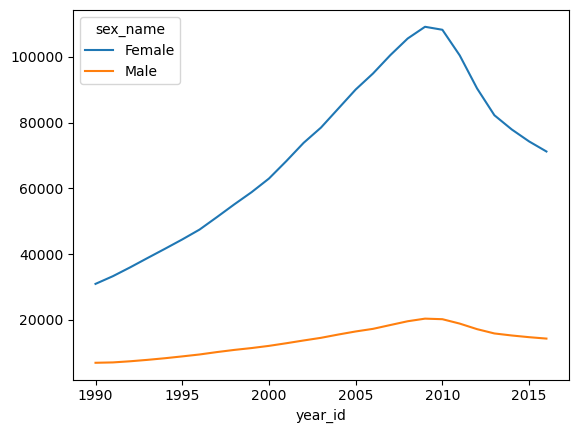

In [51]:
# %load ../src/_solutions/challenge3.py
ages = ['95 plus']
location  = ['Germany']
sex = ['Male', 'Female']

cond = (
    pop["age_group_name"].isin(ages) & 
    pop["location_name"].isin(location) & 
    pop["sex_name"].isin(sex)
)

pop_subset3 = pop.loc[cond,:]
print(pop_subset3.shape)
print(pop_subset3.sample(5))

gb3 = pop_subset3.groupby(["year_id", "sex_name"])["pop"].sum()
print(gb3)

gb3.unstack().plot()

***

In [45]:
ages = ['5-14 years', '15-49 years', '50-69 years','70+ years']
location = ["Germany", "France", "Italy", "Spain"]
sex = ['Male', 'Female']

In [46]:
def plot_population(ages=ages, location=location, sex=sex):

    cond = (
    pop["age_group_name"].isin(ages) & 
    pop["location_name"].isin(location) & 
    pop["sex_name"].isin(sex)
    )

    pop_subset = pop.loc[cond]

    gb = pop_subset.groupby(["year_id", "location_name"])["pop"].sum()
    gb = gb.unstack()

    gb.plot(figsize=(14,4))
    plt.grid()

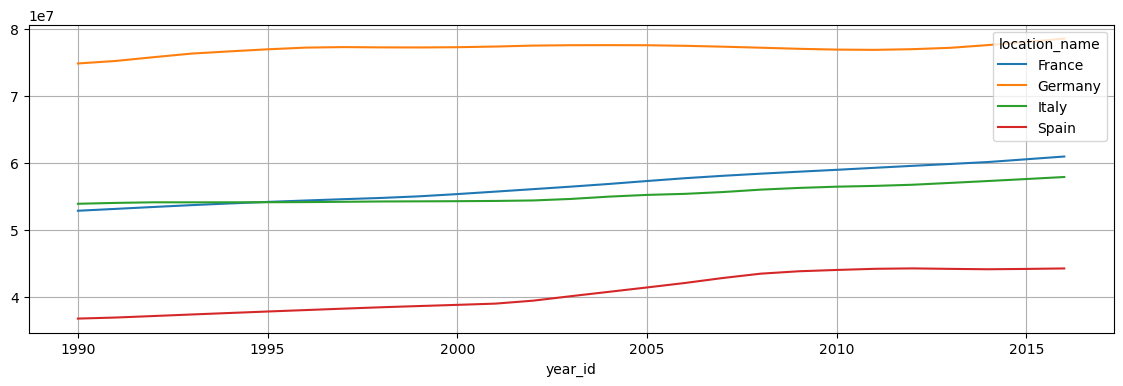

In [47]:
plot_population(ages=ages, location=location, sex=sex)